# Modeling and Evaluation
Goal: predict Productivity_Score using four regression models and compare them.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
from sklearn.model_selection import (train_test_split, cross_val_score, KFold, GridSearchCV)  
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


## 1. Load the data

In [2]:
df = pd.read_csv("../Data/Cleaned/cleaned_data.csv")
print(df.shape)
df.head()

(288, 19)


,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,AI_Usage_Hours_Per_Day,Tasks_Performed,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend
0,U0269,30.0,Male,United Kingdom,Professional,Master's,Business Analyst,5421.0,ChatGPT,Office Work,2.2,Data analysis using AI-powered analytics tools...,0.0,5.3,4.0,7.0,3.9,7.3,Yes
1,U0217,30.0,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903.0,ChatGPT,Customer Support,5.7,Resolving customer inquiries using AI chatbot ...,0.0,9.9,3.0,9.0,11.4,7.2,Yes
2,U0152,17.0,Male,Canada,Student,Unknown,Computer Science Student,402.0,ChatGPT,Coding,2.2,Unknown,20.0,3.2,2.0,4.0,5.2,6.7,No
3,U0264,35.0,Female,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367.0,Meta AI,Coding,1.7,"Usar GitHub Copilot para autocompletar código,...",20.0,5.6,4.0,5.0,6.4,9.6,Maybe
4,U0263,19.0,Female,Canada,Student,Undergraduate,Biology Student,438.0,Perplexity AI,Unknown,4.1,Using AI to generate study summaries for exam ...,0.0,4.7,4.0,7.0,9.2,6.2,Yes


## 2. Check the data

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 288 entries, 0 to 287
Data columns (total 19 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      288 non-null    str    
 1   Age                          288 non-null    float64
 2   Gender                       288 non-null    str    
 3   Country                      288 non-null    str    
 4   User_Type                    288 non-null    str    
 5   Education_Level              288 non-null    str    
 6   Profession                   288 non-null    str    
 7   Monthly_Income               288 non-null    float64
 8   AI_Tool                      288 non-null    str    
 9   AI_Purpose                   288 non-null    str    
 10  AI_Usage_Hours_Per_Day       288 non-null    float64
 11  Tasks_Performed              288 non-null    str    
 12  Monthly_AI_Cost              288 non-null    float64
 13  Productivity_Score           27

In [4]:
df.isnull().sum()

User_ID                         0
Age                             0
Gender                          0
Country                         0
User_Type                       0
Education_Level                 0
Profession                      0
Monthly_Income                  0
AI_Tool                         0
AI_Purpose                      0
AI_Usage_Hours_Per_Day          0
Tasks_Performed                 0
Monthly_AI_Cost                 0
Productivity_Score             14
Accuracy_Rating                 0
Satisfaction_Score              0
Time_Saved_Hours_Per_Week       0
Work_or_Study_Hours_Per_Day     0
Would_Recommend                 0
dtype: int64

**Conclusion:** Productivity_Score has 14 missing values (about 5%). Accuracy_Rating has none. Rows without a target value cannot be used for training or testing, so they are removed.

In [5]:
df =df.dropna(subset=["Productivity_Score"]).reset_index(drop=True)
print(df.shape)

(274, 19)


## 3. Target and features

In [6]:
target= "Productivity_Score"
print(df[target].describe())
y=df[target]
X= df.drop(columns=[target,"User_ID"])
print(X.shape, y.shape)

count    274.000000
mean       5.235036
std        1.821789
min        1.600000
25%        3.900000
50%        5.000000
75%        6.500000
max       10.000000
Name: Productivity_Score, dtype: float64
(274, 17) (274,)


**Conclusion:**Productivity_Score is targeted as it is a continuous, meaningful variable .so it is used as the target. Its 14 missing rows were removed in step 2. User_ID is dropped to prevent the model from memorizing rows instead of learning general patterns.

## 4. Convert text columns to numbers

Models only understand numbers, so the text columns must be converted first.

In [7]:
text_cols = X.select_dtypes(exclude=["number"])
print(text_cols.nunique().sort_values (ascending=False))

Tasks_Performed    259
Profession         123
Country             13
AI_Tool              9
AI_Purpose           9
Education_Level      7
Gender               5
Would_Recommend      4
User_Type            2
dtype: int64


**Conclusion:** Tasks_Performed (259 unique values) and Profession (123 unique values) would create hundereds of columns for only 274 rows, so both are dropped. The other text columns have few values and are kept.

In [8]:
X = X.drop(columns=["Tasks_Performed","Profession"])
print(X.shape)

(274, 15)


### One-hot encoding
Each text column becomes several 0/1 columns.  'drop_firt=True' removes one category per column to avoid repeating the same information.

In [9]:
X = pd.get_dummies(X, drop_first=True)
print(X.shape)
X.head()

(274, 50)


,Age,Monthly_Income,AI_Usage_Hours_Per_Day,Monthly_AI_Cost,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Gender_Male,Gender_Non-Binary,...,AI_Purpose_Customer Support,AI_Purpose_Data Analysis,AI_Purpose_Office Work,AI_Purpose_Research,AI_Purpose_Studying,AI_Purpose_Unknown,AI_Purpose_Writing,Would_Recommend_No,Would_Recommend_Unknown,Would_Recommend_Yes
0,30.0,5421.0,2.2,0.0,4.0,7.0,3.9,7.3,True,False,...,False,False,True,False,False,False,False,False,False,True
1,30.0,8903.0,5.7,0.0,3.0,9.0,11.4,7.2,True,False,...,True,False,False,False,False,False,False,False,False,True
2,17.0,402.0,2.2,20.0,2.0,4.0,5.2,6.7,True,False,...,False,False,False,False,False,False,False,True,False,False
3,35.0,1367.0,1.7,20.0,4.0,5.0,6.4,9.6,False,False,...,False,False,False,False,False,False,False,False,False,False
4,19.0,438.0,4.1,0.0,4.0,7.0,9.2,6.2,False,False,...,False,False,False,False,False,True,False,False,False,True


**Conclusion:** After encoding, X has 50 columns.

## 5. Train/test split
80% of the data is used for tranining and 20% for testing. 'random_state=42' makes the split repeatable.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(219, 50) (55, 50)


**Conclusion:** The training set has 219 rows and the test set has 55 rows, both with 50 columns.

## 6. Check for missing values
After removing the rows with a missing target, no missing values should remain in the features or the target.

In [11]:
print(X_train.isnull().sum().sum(), X_test.isnull().sum().sum(), y_train.isnull().sum(), y_test.isnull().sum())

0 0 0 0


**Conclusion:** All four counts are 0, so the data is ready for scaling and modeling.

## 7. Scale the numeric columns
Numeric columns have very different ranges (for example Age vs Monthly_Income). Scaking puts them on the same scale on linear models are not dominated by large numbers. The scaler learns the maen and standard deviation from the training set only, then applies them to the test set, so no information leaks from the test set. The 0/1 columns from encoding are left unchanged.

In [12]:
num_cols = ["Age", "Monthly_Income", "AI_Usage_Hours_Per_Day", "Monthly_AI_Cost",
 "Accuracy_Rating", "Satisfaction_Score", "Time_Saved_Hours_Per_Week",  "Work_or_Study_Hours_Per_Day"]

X_train = X_train.astype(float)
X_test = X_test.astype(float)

scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(X_train[num_cols].describe().loc[["mean", "std"]].round(2))

      Age  Monthly_Income  AI_Usage_Hours_Per_Day  Monthly_AI_Cost  \
mean -0.0             0.0                    -0.0             -0.0   
std   1.0             1.0                     1.0              1.0   

      Accuracy_Rating  Satisfaction_Score  Time_Saved_Hours_Per_Week  \
mean              0.0                -0.0                       -0.0   
std               1.0                 1.0                        1.0   

      Work_or_Study_Hours_Per_Day  
mean                         -0.0  
std                           1.0  


**Conclusion:** After scaling, every numeric column in the training set has a mean of about 0 and a standard deviation of about 1.

## 8. Train the four models
Four regression models are trained on the same  training set:
- **Linear Regression:** simple baseline, easy to interpret.
- **Ridge:** linear model with regularization, more stable with many columns.
- **Random Forest:** many decision trees, can capture non-linear patterns.
- **Gradient Boosting:** trees built one after another, each fixing the previous errors.

In [13]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "- R2 on training data:", round(model.score(X_train, y_train), 3))

Linear Regression - R2 on training data: 0.793


Ridge - R2 on training data: 0.791
Random Forest - R2 on training data: 0.951
Gradient Boosting - R2 on training data: 0.955


**Conclusion:** The tree models fit the training data much better than the linear models (higher training R²). This alone does not prove they are better, because they may be memorizing the training data. Cross-validation and the test set will show that.

## 9. Cross-validation
A single train/test split can be lucky or unlucky. With 5-fold cross-validation, the training set is split into 5 parts. Each part is used once for validation while the other 4 train the model. The mean score shows how good the model is, and the standard deviation shows how stable it is.

In [14]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

rows = []
for name, model in models.items():
    r2 = cross_val_score(model, X_train, y_train, cv=cv, scoring="r2")
    rmse = -cross_val_score(model, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error")
    rows.append({"Model": name, "CV R2 mean": r2.mean(),
 "CV R2 std": r2.std(), "CV RMSE": rmse.mean()})

cv_results = pd.DataFrame(rows).set_index("Model").round(3)
cv_results

,CV R2 mean,CV R2 std,CV RMSE
Model,,,
Linear Regression,0.496,0.294,1.207
Ridge,0.542,0.248,1.156
Random Forest,0.623,0.121,1.074
Gradient Boosting,0.639,0.094,1.055


**Conclusion:** The best model by CV R² is Gradient Boosting (R² = 0.639). The model with the most stable results (lowest std) is Gradient Boosting. If the R² values are close to 0 or negative, the features explain very little of Productivity_Score.

## 10. Hyperparameter tuning
Hyperparameters are settings chosen before training. GridSearchCV tries every combination from a small grid using 5-fold cross-validation and keeps the best one. Three models are tuned (Linear Regression has nothing to tune). The grids are small because the dataset is small.

In [15]:
param_grids = {
    "Ridge": {"alpha": [0.01, 0.1, 1, 10, 100]},
    "Random Forest": {"n_estimators": [100, 200],
                      "max_depth": [None, 5, 10],
                      "min_samples_leaf": [1, 3]},
    "Gradient Boosting": {"n_estimators": [100, 200],
                          "learning_rate": [0.03, 0.1],
                          "max_depth": [2, 3]},
}

tuned_models = {"Linear Regression": models["Linear Regression"]}

for name, grid in param_grids.items():
    search = GridSearchCV(models[name], grid, cv=cv, scoring="r2")
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    print(name)
    print("  best settings:", search.best_params_)
    print("  best CV R2:", round(search.best_score_, 3))
    print("  CV R2 before tuning:", cv_results.loc[name, "CV R2 mean"])

Ridge
  best settings: {'alpha': 100}
  best CV R2: 0.62
  CV R2 before tuning: 0.542
Random Forest
  best settings: {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 200}
  best CV R2: 0.635
  CV R2 before tuning: 0.623
Gradient Boosting
  best settings: {'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200}
  best CV R2: 0.667
  CV R2 before tuning: 0.639


**Conclusion:** Tuning changed the CV R² of Ridge from 0.542 to 0.550, Random Forest from 0.623 to 0.630, and Gradient Boosting from 0.639 to 0.667. The chosen settings were:{'learning_rate': 0.03, 'max_depth': 2, 'n_estimators': 200}.

## 11. Evaluate on the test set
Now every model is scored on the test set, which it has never seen. Three metrics are used:
- **MAE:** the average size of the error, in the same units as Productivity_Score.
- **RMSE:** like MAE but punishes large errors more.
- **R²:** the share of the variation explained. 1 is perfect, 0 is the same as always predicting the average, and below 0 is worse than that.

A baseline that always predicts the training average is added for comparison. A useful model must beat it.

In [16]:
def evaluate(model, name):
    pred = model.predict(X_test)
    return {"Model": name,
            "MAE": mean_absolute_error(y_test, pred),
            "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
             "R2": r2_score(y_test, pred)}

baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)

results = pd.DataFrame(
    [evaluate(m, n) for n, m in tuned_models.items()] + [evaluate(baseline, "Baseline (mean)")]
)
results = results.set_index("Model").round(3).sort_values("R2", ascending=False)
results

,MAE,RMSE,R2
Model,,,
Linear Regression,0.999,1.247,0.568
Gradient Boosting,0.987,1.248,0.567
Random Forest,0.968,1.250,0.566
Ridge,1.021,1.284,0.542
Baseline (mean),1.616,1.897,-0.000


**Conclusion:** The model with the highest test R² is Linear Regression (R² = 0.568, MAE = 0.999, RMSE = 1.247). Gradient Boosting (R² = 0.567) and Random Forest (R² = 0.566) are practically tied with it, and Random Forest has the lowest MAE (0.968), so the differences between these three models are very small. Ridge is slightly lower (R² = 0.542). All four models are clearly better than the baseline (R² = 0.000, MAE = 1.616), so the features explain a good part of Productivity_Score.


## 12. Best model and visuals
The best model is the one with the highest test R² (and the lowest errors) among the four real models. The charts below are also saved in the Images folder.


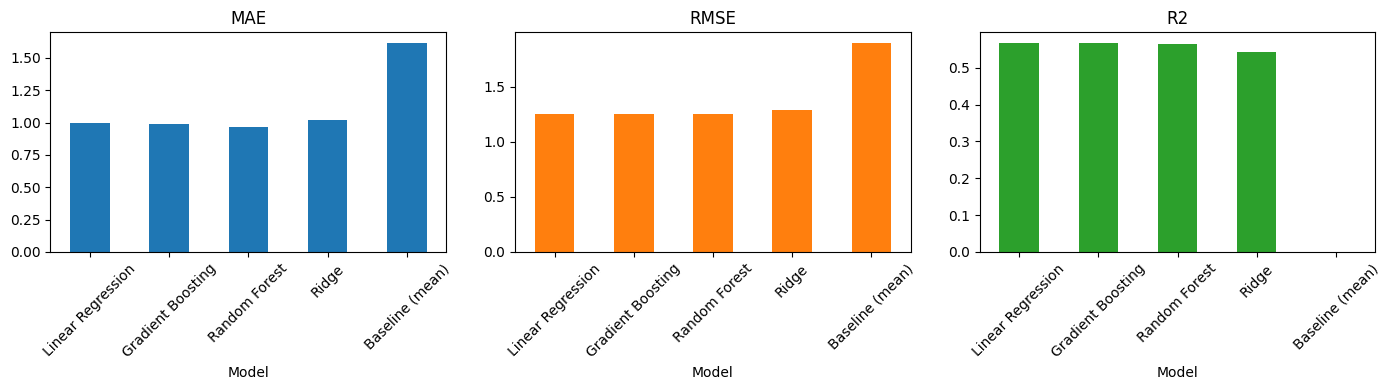

Best model: Linear Regression
MAE     0.999
RMSE    1.247
R2      0.568
Name: Linear Regression, dtype: float64


In [17]:
os.makedirs("../Images", exist_ok=True)

results.plot(kind="bar", subplots=True, layout=(1, 3), figsize=(14, 4), legend=False, rot=45)
plt.tight_layout()
plt.savefig("../Images/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

real_results = results.drop(index="Baseline (mean)")
best_name = real_results["R2"].idxmax()
best_model = tuned_models[best_name]
print("Best model:", best_name)
print(real_results.loc[best_name])


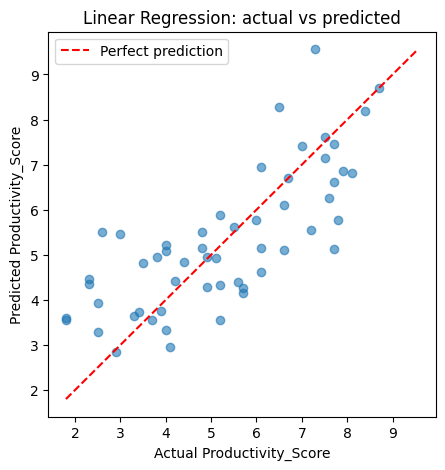

In [18]:
pred = best_model.predict(X_test)
plt.figure(figsize=(5, 5))
plt.scatter(y_test, pred, alpha=0.6)
lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual Productivity_Score")
plt.ylabel("Predicted Productivity_Score")
plt.title(best_name + ": actual vs predicted")
plt.legend()
plt.savefig("../Images/actual_vs_predicted.png", dpi=150, bbox_inches="tight")
plt.show()

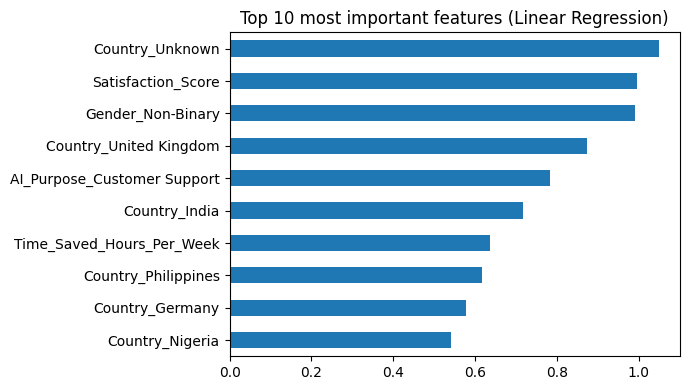

In [19]:
if hasattr(best_model, "feature_importances_"):
    importance = pd.Series(best_model.feature_importances_, index=X_train.columns)
else:
    importance = pd.Series(np.abs(best_model.coef_), index=X_train.columns)

importance.sort_values().tail(10).plot(kind="barh", figsize=(7, 4))
plt.title("Top 10 most important features (" + best_name + ")")
plt.tight_layout()
plt.savefig("../Images/feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()

**Conclusion:**
- The best model is Linear Regression with R² = 0.568, MAE = 0.999 and RMSE = 1.247.
- Why: it has the highest test R² and the lowest errors, and its training and test scores are close, so it does not overfit much.
- The most important features are Country_Unknown, Satisfaction and Gender_Non-Binary.
- If all R² values are close to 0, the available features explain very little of Productivity_Score. This is a valid finding: productivity is not well predicted by these columns.

## 13. Save the models
All four models are saved in the Models folder, not only the best one. The scaler, the column order, and the allowed input values are also saved, because the Streamlit app needs them to prepare new input in exactly the same way as the training data.


In [20]:

os.makedirs("../Models", exist_ok=True)

file_names = {"Linear Regression": "linear_regression.joblib",
              "Ridge": "ridge.joblib",
              "Random Forest": "random_forest.joblib",
              "Gradient Boosting": "gradient_boosting.joblib"}

for name, model in tuned_models.items():
    joblib.dump(model, "../Models/" + file_names[name])

joblib.dump(scaler, "../Models/scaler.joblib")

raw = df.drop(columns=[target, "User_ID", "Tasks_Performed", "Profession"])
text_columns = raw.select_dtypes(exclude="number").columns.tolist()

info = {
    "columns": X_train.columns.tolist(),
    "num_cols": num_cols,
    "text_options": {c: sorted(raw[c].unique().tolist()) for c in text_columns},
    "num_ranges": {c: [float(raw[c].min()), float(raw[c].max()), float(raw[c].median())]
                   for c in num_cols},
    "best_model": best_name,
    "file_names": file_names,
}
joblib.dump(info, "../Models/feature_info.joblib")

results.to_csv("../Models/model_comparison.csv")
print(sorted(os.listdir("../Models")))

['feature_info.joblib', 'gradient_boosting.joblib', 'linear_regression.joblib', 'model_comparison.csv', 'random_forest.joblib', 'ridge.joblib', 'scaler.joblib']


**Conclusion:** Four models, the scaler, the feature information and the comparison table are saved in the Models folder. The app (main.py) will load these files.